In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np

DATA_DIR = "/content/drive/MyDrive/fintech_theme3/data"
train = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=["Date"])
valid = pd.read_csv(f"{DATA_DIR}/valid.csv", parse_dates=["Date"])
test  = pd.read_csv(f"{DATA_DIR}/test.csv",  parse_dates=["Date"])
px    = pd.read_csv(f"{DATA_DIR}/prices.csv", parse_dates=["Date"])

# Признаки из этапа 1
FEATURES_1 = ["ret_1", "ret_5", "ret_20", "momentum_60", "volatility_5",
              "volatility_20", "ma_ratio_20", "ma_ratio_60",
              "volume_change", "relative_volume_20"]
print(train.shape, valid.shape, test.shape, px.shape)

Mounted at /content/drive
(20220, 13) (4300, 13) (4350, 13) (29630, 4)


In [2]:
px = px.sort_values(["Ticker", "Date"]).reset_index(drop=True)
gc = px.groupby("Ticker")["Close"]
gv = px.groupby("Ticker")["Volume"]
px["r"] = gc.pct_change()  # вспомогательная дневная доходность (в модель не идёт)

def rsi(s, n=14):
    d = s.diff()
    up = d.clip(lower=0).ewm(alpha=1/n, adjust=False).mean()
    down = (-d.clip(upper=0)).ewm(alpha=1/n, adjust=False).mean()
    return 100 - 100 / (1 + up / down)

# --- Технические индикаторы по каждой акции ---
px["rsi_14"]       = gc.transform(lambda s: rsi(s).shift(1))
px["macd"]         = gc.transform(lambda s: (s.ewm(span=12, adjust=False).mean()
                                             / s.ewm(span=26, adjust=False).mean() - 1).shift(1))
px["zscore_20"]    = gc.transform(lambda s: ((s - s.rolling(20).mean())
                                             / s.rolling(20).std()).shift(1))
px["vol_ratio"]    = gc.transform(lambda s: (s.pct_change().rolling(5).std()
                                             / s.pct_change().rolling(20).std()).shift(1))
px["drawdown_252"] = gc.transform(lambda s: (s / s.rolling(252).max() - 1).shift(1))
px["mom_12_1"]     = gc.transform(lambda s: (s.shift(21) / s.shift(252) - 1).shift(1))
px["volume_trend"] = gv.transform(lambda v: (v.rolling(5).mean()
                                             / v.rolling(60).mean()).shift(1))
px["_ret_20"]      = gc.transform(lambda s: s.pct_change(20).shift(1))  # вспомогательный

# --- Рыночные признаки (среднее по 10 акциям) ---
mkt = px.groupby("Date")["r"].mean().sort_index()
mkt_idx = (1 + mkt.fillna(0)).cumprod()
m = pd.DataFrame({
    "mkt_ret_5":  mkt_idx.pct_change(5).shift(1),
    "mkt_ret_20": mkt_idx.pct_change(20).shift(1),
    "mkt_vol_20": mkt.rolling(20).std().shift(1),
})
px = px.merge(m, left_on="Date", right_index=True, how="left")

# --- Относительная сила акции ---
px["rel_ret_20"]  = px["_ret_20"] - px["mkt_ret_20"]
px["rank_ret_20"] = px.groupby("Date")["_ret_20"].rank(pct=True)

NEW_FEATURES = ["rsi_14", "macd", "zscore_20", "vol_ratio", "drawdown_252",
                "mom_12_1", "volume_trend", "mkt_ret_5", "mkt_vol_20",
                "rel_ret_20", "rank_ret_20"]
ALL_FEATURES = FEATURES_1 + NEW_FEATURES

# Присоединяем к готовым выборкам (разбиение из этапа 1 не меняется)
cols = ["Date", "Ticker"] + NEW_FEATURES
train = train.merge(px[cols], on=["Date", "Ticker"], how="left")
valid = valid.merge(px[cols], on=["Date", "Ticker"], how="left")
test  = test.merge(px[cols],  on=["Date", "Ticker"], how="left")

# Убираем inf и строки, где окна (до 252 дней) ещё не набрались
for d in (train, valid, test):
    d[ALL_FEATURES] = d[ALL_FEATURES].replace([np.inf, -np.inf], np.nan)
train = train.dropna(subset=ALL_FEATURES)
valid = valid.dropna(subset=ALL_FEATURES)
test  = test.dropna(subset=ALL_FEATURES)

print("Train:", train["Date"].min().date(), "—", train["Date"].max().date(), train.shape)
print("Valid:", valid.shape, " Test:", test.shape)

Train: 2016-01-05 — 2023-04-12 (18300, 24)
Valid: (4300, 24)  Test: (4350, 24)


Признакам drawdown_252 и mom_12_1 нужен год истории, поэтому train теперь начнётся примерно с 2016 года.

In [3]:
new_info = {
    "rsi_14":       "Индекс относительной силы: >70 перекупленность, <30 перепроданность",
    "macd":         "Отношение быстрой EMA(12) к медленной EMA(26) — сила и смена тренда",
    "zscore_20":    "Сколько ст. отклонений цена выше/ниже средней за 20 дней (полосы Боллинджера)",
    "vol_ratio":    "Волатильность 5 дн. / 20 дн. — рост риска в последние дни",
    "drawdown_252": "Падение от максимума за год — насколько акция «просела»",
    "mom_12_1":     "Классический моментум: доходность за год без последнего месяца",
    "volume_trend": "Средний объём 5 дн. / 60 дн. — приток или отток интереса инвесторов",
    "mkt_ret_5":    "Доходность «рынка» (среднее 10 акций) за 5 дней — общий фон",
    "mkt_vol_20":   "Волатильность рынка за 20 дней — режим риска на рынке",
    "rel_ret_20":   "Доходность акции минус доходность рынка за 20 дней — относительная сила",
    "rank_ret_20":  "Место акции среди 10 по доходности за 20 дней (0–1)",
}
display(pd.DataFrame({
    "Тип": train[NEW_FEATURES].dtypes.astype(str),
    "Экономический смысл": pd.Series(new_info),
}))

,Тип,Экономический смысл
rsi_14,float64,Индекс относительной силы: >70 перекупленность...
macd,float64,Отношение быстрой EMA(12) к медленной EMA(26) ...
zscore_20,float64,Сколько ст. отклонений цена выше/ниже средней ...
vol_ratio,float64,Волатильность 5 дн. / 20 дн. — рост риска в по...
drawdown_252,float64,Падение от максимума за год — насколько акция ...
mom_12_1,float64,Классический моментум: доходность за год без п...
volume_trend,float64,Средний объём 5 дн. / 60 дн. — приток или отто...
mkt_ret_5,float64,Доходность «рынка» (среднее 10 акций) за 5 дне...
mkt_vol_20,float64,Волатильность рынка за 20 дней — режим риска н...
rel_ret_20,float64,Доходность акции минус доходность рынка за 20 ...


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, accuracy_score

y_train, y_valid = train["target"], valid["target"]

def fit_logreg(features):
    model = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    )
    model.fit(train[features], y_train)
    p = model.predict_proba(valid[features])[:, 1]
    auc = roc_auc_score(y_valid, p)
    return model, {
        "ROC-AUC": round(auc, 4),
        "Gini": round(2 * auc - 1, 4),
        "Accuracy": round(accuracy_score(y_valid, (p > 0.5).astype(int)), 4),
    }

_, m1 = fit_logreg(FEATURES_1)
base, m_all = fit_logreg(ALL_FEATURES)

results = pd.DataFrame({
    "LogReg (10 признаков этапа 1)": m1,
    "LogReg (все 21 признак)": m_all,
}).T
results["Наивный прогноз «всегда рост», Accuracy"] = round(y_valid.mean(), 4)
display(results)

,ROC-AUC,Gini,Accuracy,"Наивный прогноз «всегда рост», Accuracy"
LogReg (10 признаков этапа 1),0.4805,-0.0389,0.4874,0.5702
LogReg (все 21 признак),0.4936,-0.0129,0.4891,0.5702


,Коэффициент (стандартизованный)
macd,-0.108770
ma_ratio_60,-0.088820
volatility_5,-0.071727
relative_volume_20,-0.057437
volume_trend,-0.039025
ret_5,-0.032611
ret_1,-0.019603
drawdown_252,-0.018074
zscore_20,-0.010923
rsi_14,-0.009005


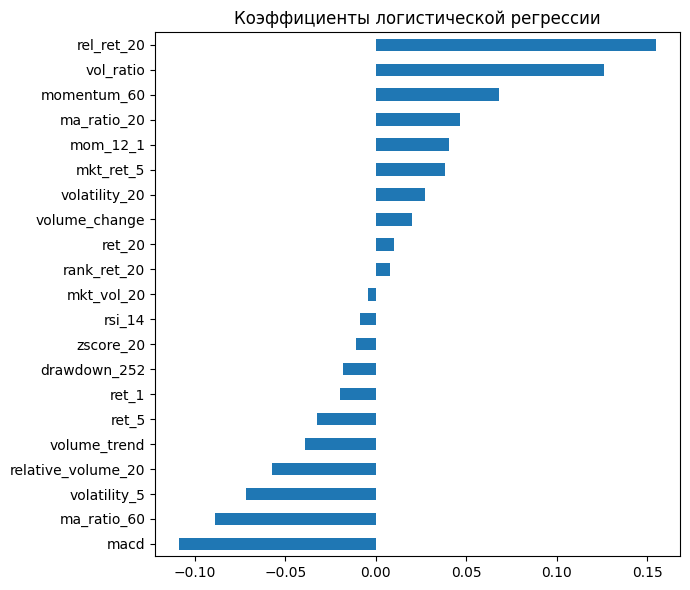

In [5]:
coefs = pd.Series(base[-1].coef_[0], index=ALL_FEATURES).sort_values()
display(coefs.to_frame("Коэффициент (стандартизованный)"))

import matplotlib.pyplot as plt
coefs.plot(kind="barh", figsize=(7, 6), title="Коэффициенты логистической регрессии")
plt.tight_layout(); plt.show()

Положительный коэффициент означает, что признак повышает вероятность роста, отрицательный — понижает.

In [6]:
import json
train.to_csv(f"{DATA_DIR}/train_fe.csv", index=False)
valid.to_csv(f"{DATA_DIR}/valid_fe.csv", index=False)
test.to_csv(f"{DATA_DIR}/test_fe.csv", index=False)   # test по-прежнему не оцениваем!
with open(f"{DATA_DIR}/baseline_metrics.json", "w") as f:
    json.dump(m_all, f)
print("Сохранено")

Сохранено


In [7]:
# 1. Качество на train и validation
p_tr = base.predict_proba(train[ALL_FEATURES])[:, 1]
p_va = base.predict_proba(valid[ALL_FEATURES])[:, 1]
print("ROC-AUC train:", round(roc_auc_score(y_train, p_tr), 4),
      "| validation:", round(roc_auc_score(y_valid, p_va), 4))

# 2. ROC-AUC по каждой акции на validation
v = valid.assign(p=p_va)
print("\nROC-AUC по акциям (validation):")
print(v.groupby("Ticker").apply(lambda d: roc_auc_score(d["target"], d["p"])).round(3))

# 3. Подбор силы регуляризации C на validation
print("\nПодбор C:")
best_C, best_gini = None, -1
for C in [0.0001, 0.001, 0.01, 0.1, 1]:
    m = make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(C=C, max_iter=1000, class_weight="balanced", random_state=42),
    ).fit(train[ALL_FEATURES], y_train)
    auc = roc_auc_score(y_valid, m.predict_proba(valid[ALL_FEATURES])[:, 1])
    print(f"C={C:<7} ROC-AUC={auc:.4f}  Gini={2*auc-1:.4f}")
    if 2*auc - 1 > best_gini:
        best_C, best_gini, best_auc = C, 2*auc - 1, auc

print(f"\nЛучший C = {best_C}, Gini = {best_gini:.4f}")

# Сохраняем лучший результат как планку для бустинга
import json
baseline = {"model": "LogReg", "C": best_C,
            "ROC-AUC": round(best_auc, 4), "Gini": round(best_gini, 4)}
with open(f"{DATA_DIR}/baseline_metrics.json", "w") as f:
    json.dump(baseline, f)
print(baseline)

ROC-AUC train: 0.5416 | validation: 0.4936

ROC-AUC по акциям (validation):
Ticker
AAPL     0.514
AMZN     0.506
GOOGL    0.486
JNJ      0.443
JPM      0.450
KO       0.463
MSFT     0.467
NVDA     0.475
WMT      0.536
XOM      0.451
dtype: float64

Подбор C:


/tmp/ipykernel_4667/3755827304.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(v.groupby("Ticker").apply(lambda d: roc_auc_score(d["target"], d["p"])).round(3))


C=0.0001  ROC-AUC=0.5064  Gini=0.0129
C=0.001   ROC-AUC=0.4961  Gini=-0.0078
C=0.01    ROC-AUC=0.4936  Gini=-0.0127
C=0.1     ROC-AUC=0.4936  Gini=-0.0128
C=1       ROC-AUC=0.4936  Gini=-0.0129

Лучший C = 0.0001, Gini = 0.0129
{'model': 'LogReg', 'C': 0.0001, 'ROC-AUC': np.float64(0.5064), 'Gini': np.float64(0.0129)}


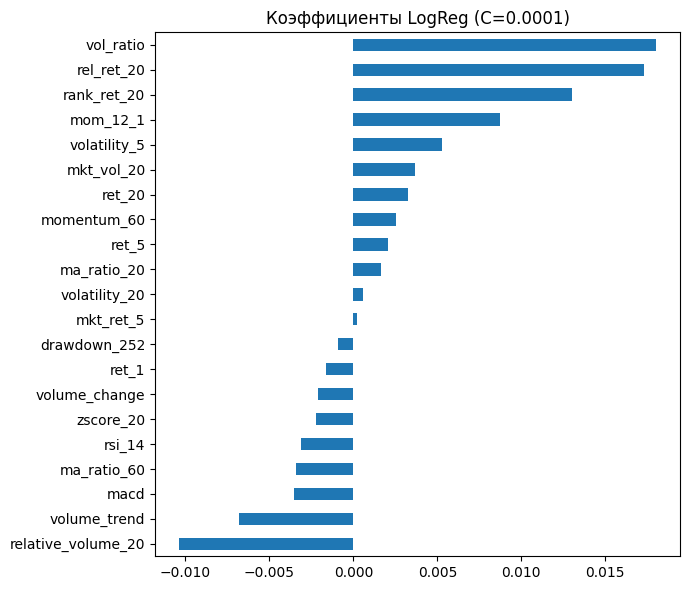

In [8]:
base = make_pipeline(
    SimpleImputer(strategy="median"), StandardScaler(),
    LogisticRegression(C=best_C, max_iter=1000, class_weight="balanced", random_state=42),
).fit(train[ALL_FEATURES], y_train)

coefs = pd.Series(base[-1].coef_[0], index=ALL_FEATURES).sort_values()
coefs.plot(kind="barh", figsize=(7, 6), title=f"Коэффициенты LogReg (C={best_C})")
plt.tight_layout(); plt.show()

К 10 признакам этапа 1 добавлено 11 новых с экономическим смыслом: технические индикаторы (RSI, MACD, z-score, просадка от годового максимума, моментум 12-1), признаки объёма и рыночные признаки (доходность и волатильность «рынка» из 10 акций, относительная сила акции). Логистическая регрессия с регуляризацией, подобранной на validation (C = 0.0001), показала ROC-AUC = 0.506, Gini = 0.013, то есть почти на уровне случайного угадывания. На train ROC-AUC = 0.54, а на validation качество падает, что указывает на смену рыночного режима: в 2023–2024 гг. рынок рос за счёт технологических компаний, и сильнее всего модель ошибается на защитных бумагах (JNJ, KO, XOM) и JPM. Наиболее значимые признаки — относительная сила акции к рынку и моментум (положительное влияние), а также отклонение от 60-дневной средней и MACD (возврат к среднему). Gini = 0.013 — планка, которую должен превзойти градиентный бустинг на этапе 3.